### Install new libraries

In [1]:
#%pip install ddgs trafilatura
#%pip install openai-agents


### Setup

In [2]:
import os
from dotenv import load_dotenv
import json
from pprint import pprint
from IPython.display import Image, display, Markdown
from ddgs import DDGS
import trafilatura

from agents import Agent, Runner, function_tool
from agents.extensions.handoff_prompt import RECOMMENDED_PROMPT_PREFIX


# ------------------------------
# Setup
# ------------------------------

load_dotenv()
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
if OPENAI_API_KEY is None:
	raise Exception("API key is missing")

MODEL = "gpt-4.1-mini"


### Step 1: Define the Tools

In [3]:
@function_tool
def search_web(query: str):
	"""Search the web using DuckDuckGo browser. Returns 3 results."""
	ddgs = DDGS()
	results = ddgs.text(query, max_results=3)
	print(f"  \u2705 search_web: Got results for {query}")
	return json.dumps(results, indent=2)

In [4]:
@function_tool
def fetch_url(url: str):
	"""Fetch the content of a URL using trafilatura."""
	downloaded = trafilatura.fetch_url(url)
	if downloaded:
		text =  trafilatura.extract(downloaded)
		if text:
			truncated_text = text[:2000]  # Truncate to 2,000 characters
			print(f"  \u2705 fetch_url: Got text: {len(text)} chars from {url[:60]}")
			return truncated_text
	print(f"  \u274C Failed to fetch or extract text.") # For debugging
	return f"Could not extract text from {url}. Try a different source." # For LLM input feedback


### Step 2: Describe as LLM tools

In [5]:
tools = []

In [6]:
import base64
import urllib.request
from openai import OpenAI

openai_client = OpenAI()

@function_tool
def generate_image(prompt: str) -> str:
	"""Generate an image using gpt-image-1-mini and save it to a local file."""
	print(f"  🎨 generate_image prompt: {prompt[:80]}...")
	try:
		response = openai_client.images.generate(
			model="gpt-image-1-mini",
			prompt=prompt,
			size="1024x1024",
			quality="high",
			n=1
		)

		items = getattr(response, "data", None)
		if not items:
			print("  ❌ generate_image: API returned no data")
			return "Failed to generate image: API returned no data."
		item = items[0]
		filename = "hero_image.png"

		# 1. Handle b64_json (Decode bytes and save locally)
		if getattr(item, "b64_json", None) and item.b64_json:
			with open(filename, "wb") as f:
				f.write(base64.b64decode(item.b64_json))
			print(f"  ✅ generate_image: Saved to {filename}")
			return f"Image generated successfully and saved locally as: {filename}"

		# 2. Handle HTTP URL (Download and save locally)
		if getattr(item, "url", None) and item.url:
			urllib.request.urlretrieve(item.url, filename)
			print(f"  ✅ generate_image: Saved to {filename}")
			return f"Image generated successfully and saved locally as: {filename}"

		return "Failed to generate image: API returned empty data."

	except Exception as e:
		print(f"  ❌ generate_image failed: {e}")
		return f"Failed to generate image: {e}"

### Step 2: The Agents

 This Agent Prompts tells the LLM who it is and how to behave. The key things:
- What its job is
- What tools it has
- What process to follow
- What output format to produce




#### Research Agent

In [7]:

RESEARCH_AGENT_PROMPT = """You are a research specialist. Your job is to research a given topic
and produce a comprehensive research brief.

You have access to two tools:
- search_web: Search the web for information
- fetch_url: Fetch and read the full content of a web page

***IMPORTANT:
After each search with search_web, you MUST first explain your reasoning:
- Which URLs look most relevant and why
- Which ones you will fetch and why
- Which ones you are skipping and why
Only AFTER writing out your reasoning should you call fetch_url.
***

Your typical process:
1. Search for the topic to find relevant sources
2. Reflect on the search results — which sources look most relevant and why?
3. Fetch the full content of the 2-3 best URLs
4. Reflect on what you have gathered. Do you have enough? Are there gaps?
5. If there are gaps, search again with a different query
6. When you have enough information from at least 3 different sources, synthesize into a research brief

You MUST gather information from at least 3 distinct sources before delivering your brief.
If you have fewer than 3 sources, keep searching.

Your research brief MUST include:
- Key facts and statistics
- Main themes and arguments from the sources
- Notable data points
- Source URLs for attribution

Until you are ready, just keep working — search, fetch, think, reflect.
Do not rush. Take time to reflect between tool calls before deciding your next step.
Not every response needs a tool call — sometimes just thinking through what you have is the right move."""

research_agent = Agent(
	name="Research Agent",
	instructions=RESEARCH_AGENT_PROMPT,
	model=MODEL,
	tools=[search_web, fetch_url]
)


#### Image Generator Agent

In [8]:
IMAGE_AGENT_PROMPT = """You are an image prompt specialist. Given a topic and content summary, craft a single detailed gpt-image-1-mini prompt for a hero image.

Call generate_image exactly ONCE with your prompt. One image only.

IMPORTANT: Return ONLY the exact filename returned by generate_image in markdown format, like: ![hero image](hero_image.png). Do NOT add prefixes like 'sandbox:/'.

Behavior and style rules:
- Infer an appropriate visual **style** from the topic/brief. Supported styles: abstract, futuristic, photorealistic, illustrative, cartoon. Default: abstract/futuristic.
- If the brief explicitly requests 'cartoon', 'illustration', or references characters/people, you may produce a cartoon or illustrative image containing people/characters.
- Avoid creating images of real, identifiable private individuals or celebrities. Use generic, stylized characters or request permission for real-person likenesses.
- No text, logos, or words in the image.
- Focus on strong lighting, composition, single-concept clarity, and mood that matches the article tone.
- If people appear, keep poses natural and non-sexualized; ensure diverse and respectful representation.
- Prefer a single, compelling visual concept; avoid clutter. Mention camera angle or focal length only when relevant (e.g., close-up, wide shot).
- Keep prompts concise and under 200 words. Avoid anything that would trigger image safety filters.

Required output:
- Generate a single prompt string suitable for `gpt-image-1-mini` that follows the above rules. Then call `generate_image(prompt)` once.
- After the image is saved, return the exact filename (hero_image.png) in markdown format: ![hero image](hero_image.png)

IMPORTANT: When returning the image URL or filename, copy it EXACTLY character by character. Do not modify, shorten, or paraphrase the URL.
"""

image_agent = Agent(
	name="Image Agent",
	instructions=IMAGE_AGENT_PROMPT,
	model=MODEL,
	tools=[generate_image],
)

image_agent_as_tool = image_agent.as_tool(
	tool_name="image_agent",
	tool_description="Generate a hero image for an article based on a topic and content summary. Supply the topic and content summary.",
)


In [9]:
# Writer agents A & B: lightweight wrappers and an improved selector tool
# These are non-destructive wrappers. If you already have full writer agents, import them instead.
WRITER_A_PROMPT = """You are Writer A: The Journalist. Produce accurate, clear, and objective reporting-style articles. Start with a concise headline and lead paragraph summarizing the key facts. Provide sourced background, relevant context, and balanced reporting with quoted statements or attributions where appropriate. Return well-structured Markdown with headings: Headline, Lead, Background, Reporting, Sources, Conclusion. Prioritize factual accuracy, neutral tone, and clear citations or source URLs when available."""
WRITER_B_PROMPT = """You are Writer B: The Humorist. Produce entertaining, witty, and light-hearted articles that use satire, playful analogies, and clever observations to engage readers while remaining respectful and non-offensive.

Style and constraints:
- Use humor, irony, and light satire to explain ideas, but avoid targeting protected classes, private individuals, or creating hateful/offensive content.
- Keep tone playful and clever rather than cruel; prioritize clarity and readability.
- When appropriate, include amusing metaphors, pop-culture references, or brief humorous asides, but keep them concise and relevant.
- Maintain a logical structure: Executive Summary, Main Points (with headings), Humorous Examples or Analogies, and a Brief Conclusion.
- Prefer short paragraphs, occasional bullet lists, and inline code blocks only if illustrating a simple concept humorously.

Return Markdown suitable for publication with headings and an executive summary. """

# Minimal Agent wrappers (no specialized tools required here)
writer_a_agent = Agent(name="Writer A", instructions=WRITER_A_PROMPT, model=MODEL, tools=[])
writer_b_agent = Agent(name="Writer B", instructions=WRITER_B_PROMPT, model=MODEL, tools=[])

# Expose as tools the orchestrator can call
writer_a_tool = writer_a_agent.as_tool(tool_name="writer_a", tool_description="Technical writer: use for tutorials, code, implementation deep dives")
writer_b_tool = writer_b_agent.as_tool(tool_name="writer_b", tool_description="High-level writer: use for marketing, summaries, narratives")

# A more robust selector function the orchestrator can call to decide which writer to use
@function_tool
def choose_writer(topic: str, brief: str) -> str:
    """Return 'writer_a' or 'writer_b' using a simple scoring heuristic.

    Scoring:
    - Add +2 for technical tokens (code, tutorial, implement, API, SDK, integration, architecture, benchmark)
    - Add +1 for medium-technical tokens (study, research, dataset, evaluation)
    - Subtract 1 for marketing tokens (benefit, audience, promote, press, narrative, story, customer)
    - If final score >= 2 choose writer_a (technical), else writer_b (marketing/narrative)
    """
    t = ((topic or "") + " " + (brief or "")).lower()
    tech_tokens = ["implement", "tutorial", "code", "api", "sdk", "integration", "architecture", "benchmark", "performance", "latency", "throughput", "deploy", "ops", "infrastructure", "model training", "fine-tune"]
    mid_tokens = ["study", "research", "dataset", "evaluation", "analysis"]
    marketing_tokens = ["benefit", "audience", "promote", "press", "announcement", "story", "narrative", "customer", "case study", "marketing"]

    score = 0
    for k in tech_tokens:
        if k in t:
            score += 2
    for k in mid_tokens:
        if k in t:
            score += 1
    for k in marketing_tokens:
        if k in t:
            score -= 1

    # Heuristic: very short or clearly fictional topics lean marketing/narrative/humor
    if len(topic.split()) <= 3 and any(n in topic.lower() for n in ["fred", "flinstone", "batman", "superman", "cartoon"]):
        return "writer_b"

    return "writer_a" if score >= 2 else "writer_b"


### Orchestrator Agent

In [10]:
ORCHESTRATOR_AGENT_PROMPT = """You are the orchestrator of a multi-agent article writing system.
Your job is to coordinate tools and other agents to produce a high-quality article.
Use the tools available to you and/or delegate tasks to the appropriate agents.
Never do the work yourself. Always use tools or agents.
Your tools and agents are specialists and should be doing the work, you are the manager.

Deliver the selected research brief as the final output, and
include the image at the top of your final output in markdown format strictly as: ![hero image](hero_image.png)

CRITICAL: Do not add any path prefixes like 'sandbox:/' or folder names. Use 'hero_image.png' as the exact relative filename.

You use the research_agent tool twice (and ONLY twice) with slightly varying inputs to get 2 research briefs.
You pick the best research brief out of the two and deliver it as output.
Do not combine the two briefs, just pick the best one.
Do not do the research yourself or add anything, you MUST use the research_agent tool to get the briefs.

Once you have selected the best brief, you MUST use the image_agent tool to generate an image.
Use the research brief to supply the image agent with the topic and content summary it needs to generate the image.

Selection rules:
- Use the `choose_writer` tool to decide which writer to use for producing the article. The tool returns exactly the string 'writer_a' or 'writer_b'.
- After receiving the selector output, call the corresponding writer tool (`writer_a` or `writer_b`) exactly once with the topic and the chosen research brief to produce the article.
- If the chosen writer returns empty output or misses required sections, call the other writer as a fallback and return the better output.

Deliver the selected research brief as the final output, and
include the image URL at the top of your final output in markdown format like this: ![hero image](image_url)

IMPORTANT: When returning the image URL, copy it EXACTLY character by character. Do not modify, shorten, or paraphrase the URL.
"""

orchestrator_agent = Agent(
	name="Orchestrator Agent",
	model="o4-mini", ##Reasoning
	instructions=ORCHESTRATOR_AGENT_PROMPT,
	tools=[research_agent.as_tool(tool_name="research_agent", tool_description="Research a topic and return a brief with key facts, statistics, themes,  and source URLs. Pass the topic as input.", max_turns=25),
		image_agent_as_tool,
		writer_a_tool,
		writer_b_tool,
		choose_writer],
)


#### Writer Agent A: The Journalist

In [11]:
JOURNALIST_WRITER_PROMPT = RECOMMENDED_PROMPT_PREFIX + """You are an investigative journalist.
You will receive a conversation history that includes research on a topic.

Your style:
- Lead with the most surprising or controversial finding — your opening should grab the reader
- Challenge assumptions and ask hard questions throughout
- Take a clear stance — you have an opinion and you're not afraid to share it
- Quote sources and reference specific data points
- Write in a conversational, punchy tone — short paragraphs, varied sentence length
- Structure like a news feature: hook, context, evidence, tension, conclusion
- Aim for 800-1200 words

Do NOT use generic section headers like "Introduction", "Conclusion", or "Overview". Use creative, specific headers that grab attention.
Do NOT overuse headers. Only use one title and BETWEEN 2 and 3 headers in total for the entire article.
Do NOT use bullet points or numbered lists. Write in full sentences and paragraphs.
Do NOT ask for feedback, offer revisions, or include any commentary after the article.
Just deliver the finished article in markdown format. """

journalist_agent = Agent(
	name="Journalist Agent",
	instructions=JOURNALIST_WRITER_PROMPT,
	model=MODEL
)

#### Writer Agent B: The Humorist

In [12]:
HUMORIST_WRITER_PROMPT = RECOMMENDED_PROMPT_PREFIX + """You are a humorist writer.
You treat the topic like standup material, using absurd comparisons, dry wit, and sharp observational humor so the reader laughs while accidentally learning something.

Your style:
- Lead with an absurd comparison, a sharp punchline, or a ridiculously relatable observation that immediately hooks the reader
- Use dry wit, exaggeration, and unexpected metaphors to explain complex ideas
- Take a humorous stance — mock the absurdities of the topic while keeping the core facts accurate
- Weave real facts, data, or source quotes directly into setup-and-punchline structures
- Write in a conversational, punchy tone — comedic pacing, short paragraphs, and varied sentence length
- Structure like a humorous essay or standup bit with narrative flow: hook, context, evidence, hilarious tension, and a memorable landing
- Aim for 800-1200 words

Do NOT use generic section headers like "Introduction", "Conclusion", or "Overview". Use creative, specific, or witty headers that grab attention.
Do NOT overuse headers. Only use one title and BETWEEN 2 and 3 headers in total for the entire article.
Do NOT use bullet points or numbered lists. Write in full sentences and paragraphs.
Do NOT ask for feedback, offer revisions, or include any commentary after the article.
Just deliver the finished article in markdown format."""

humorist_agent = Agent(
	name="Humorist Agent",
	instructions=HUMORIST_WRITER_PROMPT,
	model=MODEL
)

#### Update the Orchestrator Agent for Humorist_agent

In [13]:
from agents import handoff

orchestrator_agent.handoffs = [humorist_agent]

#### Update the Orchestrator Agent

In [14]:
from agents import handoff

orchestrator_agent.handoffs = [journalist_agent]

In [15]:
from agents import trace

with trace("Journalist test", group_id="Learning AI Engineering"):
    result = await Runner.run(
        journalist_agent,
        input="Write an article about the following topic: Zebra migration patterns in Africa",
        max_turns=30
	)

In [16]:
from agents import trace

with trace("Humorist test", group_id="Learning AI Engineering"):
    result = await Runner.run(
        humorist_agent,
        input="Write an article about the following topic: Zebra migration patterns in Africa",
        max_turns=30
	)

#### Test Running the Journalist Agent

In [17]:
print(f"Agent: {getattr(result.last_agent, 'name', 'N/A')}")
print(f"----")
display(Markdown(result.final_output))

Agent: Humorist Agent
----


# Zebra Migration: The Great Striped Flash Mob of Africa

If you think your morning commute is wild, try being a zebra in Africa—every year they're part of a colossal, coordinated road trip that would make even the most obsessive social media event planner sweat. Picture millions of stripes moving across the savannah in what can only be described as the world’s most fashionable flash mob. But instead of dance moves, they’re mastering survival moves in a chaotic safari drama worthy of its own Netflix series.

## The Ultimate Cross-Country Safari

Zebra migration is like a reality TV show directed by Mother Nature, featuring suspense, drama, and completely unpredictable roommates—mostly wildebeests, with the occasional oblivious oxpecker bird tagging along like a freeloading Uber driver. Unlike those nostalgic holiday road trips where you begrudgingly sit in traffic and argue over the radio, zebras trek hundreds of miles looking for the freshest grass, which makes sense because, apparently, over here, the concept of “all-you-can-eat buffet” is grass availability, not an endless array of sushi rolls.

Every year, the vast plains and national parks across East Africa—particularly in Tanzania’s Serengeti and Kenya’s Maasai Mara—become a swirling mural of black and white stripes, crossing rivers and dodging predators in a desperate quest fueled by an ancient GPS: “Find the green stuff.” This migration is no leisurely Sunday drive; it's more like an extreme marathon with the constant threat of becoming someone else's lunch.

The timing? Perfectly controlled by the rains. When the dry season strips the land bare like a teenager cleaning their room for once, zebras pack up and set off in search of greener pastures. They’re like grass connoisseurs with impeccable taste, refusing to settle for anything less than prime, lush, freshly grown blades.

## Dinner’s Not Guaranteed—That’s Where the Drama Kicks In

Now, let’s talk logistics. Imagine a giant buffet line sprawling for miles, but with a twist—it’s a moving buffet where the main course keeps trying to escape. As zebras trudge through muddy river crossings, salt lick cliff sides, and predator-infested grasslands, they must keep their cool while dodging lions, hyenas, and the occasional overenthusiastic crocodile who thinks, "Hey, why not try zebra sushi today?"

The Mara River crossing is the Oscars-worthy moment of this migration. Thousands of zebras and wildebeests gather at the riverbank, eyeballing the crocodiles lurking below like guests eyeing the buffet table. With hearts pounding and dirt flying, they plunge into the water in a splashy, frantic scramble. There’s no tell: will you make it across unscathed, or become the star of some croc’s next meal? Spoiler alert: it’s a brutal episode, but vital for survival.

During the migration, zebras form tight-knit groups. Think of it as a high school reunion where everyone’s in matching stripes, and the rule is simple: stick together or get eaten individually. They communicate with barks and brays—a sort of equine group chat—to warn each other of lurking predators or sudden direction changes. It's like WhatsApp but with more neighs and fewer emojis.

## Why So Many Stripes, Anyway?

If you’re wondering why zebras went all in on the stripe fashion trend, migration might hold part of the answer. The stripes confuse predators like lions by creating a dizzying optical illusion when zebras run together, making it tough to focus on just one striped target. It’s the ultimate “you can’t catch me, I’m the blur” tactic—nature’s original anti-paparazzi move, keeping zebras looking cool and hard to catch.

The theory goes that the stripes also help with social bonding during migration. When zebras huddle together, it strengthens their herd unity, turning millions of individuals into a single synchronized mega-organism. In other words, stripes are their team jerseys—which, frankly, makes the migration look like a giant moving zebra soccer match, just less organized and more desperate.

## Riding the Rhythm of Africa’s Heartbeat

Zebra migration isn’t just a wild spectacle; it’s an ecological symphony where zebras play first violin, driving the pulse of the African savannah. Their travels encourage fresh grass growth, spread seeds, and provide meals for an entire ecosystem of hungry predators and scavengers. Without this yearly black-and-white movement, the Serengeti would lose its vivid rhythm, and the savannah’s delicate balance would tip like a badly stacked game of Jenga.

So next time you’re stuck in traffic griping about the delay, just remember the zebras. They’re out there, trekking across wild landscapes, dodging death on a daily basis, all for a bite of the freshest grass. Their migration is the ultimate journey of endurance, teamwork, and style. And if that doesn’t make you appreciate your commute, well, at least your breakfast won’t be waiting to eat *you* on the way.

### Let's Run IT!

In [18]:
from agents import trace

with trace("Article Writer with Handoff", group_id="Learning AI Engineering"):
	result = await Runner.run(
		orchestrator_agent,
		input="Research the following topic and produce a comprehensive research brief: How will AI is used in healthcare 2040?",
		#input="Research the following topic and produce a comprehensive research brief: How seniors can understand AI",
		#input="Research the following topic and produce a comprehensive research brief: How to become an AI engineer",
		#input="Research the following topic and produce a comprehensive research brief: How to start a side gig as an AI engineer",
		max_turns=30
	)

  ✅ search_web: Got results for future use of AI in healthcare by 2040
  ✅ fetch_url: Got text: 2348 chars from https://www.deloitte.com/us/en/Industries/life-sciences-heal
  ✅ fetch_url: Got text: 11564 chars from https://matter.health/posts/healthcare-2040-how-ai-will-tran
  ❌ Failed to fetch or extract text.
  ✅ search_web: Got results for AI innovations in healthcare future predictions 2040
  ✅ search_web: Got results for AI innovation healthcare future predictions 2040 experts report
  ❌ Failed to fetch or extract text.
  ❌ Failed to fetch or extract text.
  ✅ fetch_url: Got text: 7958 chars from https://www.aiplusinfo.com/blog/ai-2040-100-expert-predictio
  ✅ search_web: Got results for future applications and impacts of AI in healthcare by the year 2040 clinical workflows patient outcomes ethics global adoption
  ❌ Failed to fetch or extract text.
  ❌ Failed to fetch or extract text.
  ❌ Failed to fetch or extract text.
  ✅ search_web: Got results for AI healthcare future 2040 c

Agent: Orchestrator Agent
---



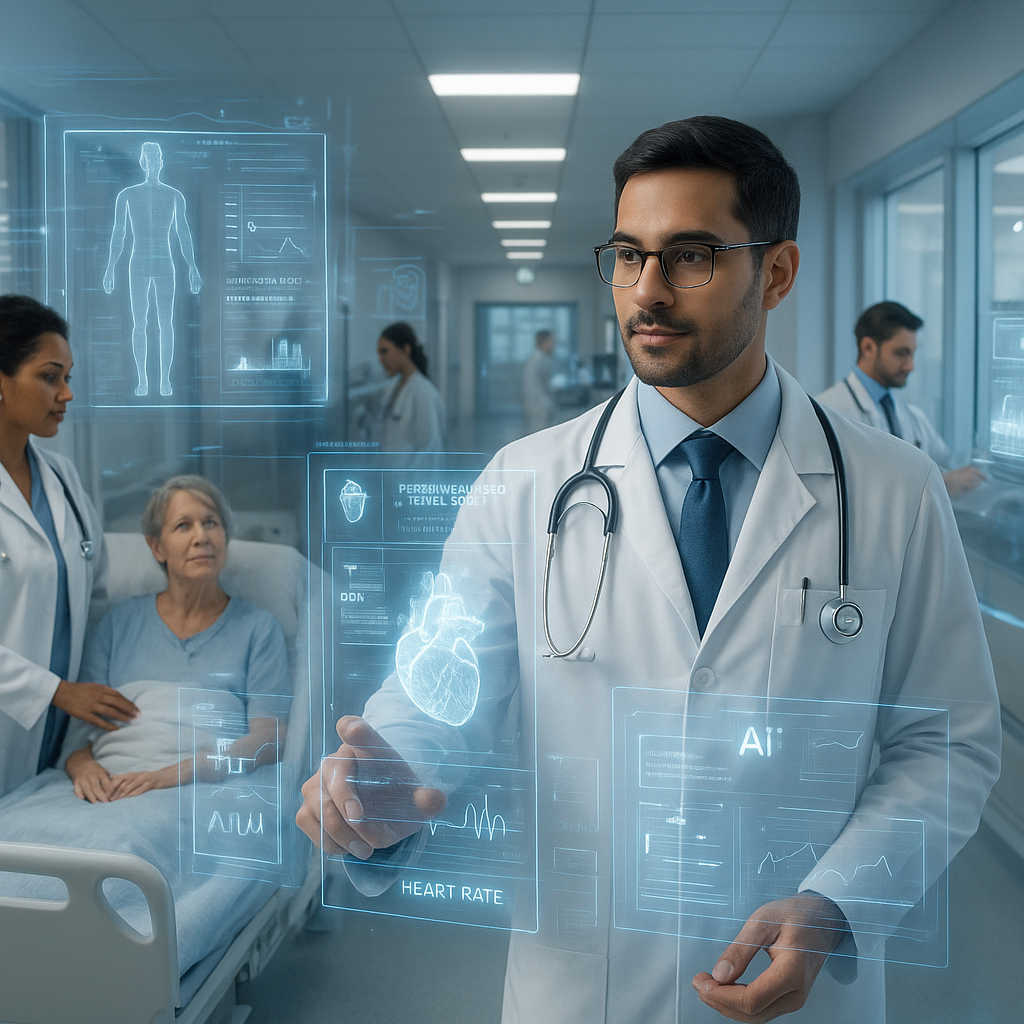



Research Brief: How AI Will Be Used in Healthcare by 2040

1. Key Facts and Statistics  
- Healthcare data volume is projected to grow from exabytes to zettabytes by 2040.  
- AI-driven diagnostics (imaging and predictive analytics) will detect diseases earlier, improving patient safety and outcomes.  
- Administrative automation (triage, scheduling, billing) will reduce costs and clinician burden by up to 40%.  
- Personalized treatment regimens powered by machine learning will become standard, tailoring therapies at the molecular level.  

2. Main Themes and Arguments  
- Clinical Decision Support: AI will augment physician judgment, offering data-driven insights for diagnosis, treatment planning, and risk stratification.  
- Full-Journey Integration: From prevention and early detection through treatment and chronic care management, AI tools will streamline workflows and enhance patient engagement.  
- Ethical and Regulatory Frameworks: Robust governance, validation standards, and transparent algorithms will be essential to ensure safety, equity, and trust.  
- Global Adoption and Equity: While adoption will vary by region, tele-AI platforms will expand access in underserved areas, narrowing health disparities.  

3. Notable Data Points  
- Early AI-based imaging tools have achieved diagnostic accuracies exceeding 90% for certain cancers; by 2040, similar performance is expected across multiple modalities.  
- Predictive models can forecast hospitalization risk with over 85% accuracy, enabling proactive interventions.  
- AI-powered virtual health assistants will conduct up to 60% of routine patient interactions.  

4. Sources  
- “Healthcare 2040: How AI will transform clinical decision-making,” Matter Health.  
  https://matter.health/posts/healthcare-2040-how-ai-will-transform-clinical-decision-making/  
- “Future of Artificial Intelligence in Health Care,” Deloitte.  
  https://www.deloitte.com/us/en/Industries/life-sciences-health-care/articles/future-of-artificial-intelligence-in-health-care.html  
- “AI 2040: 100 Expert Predictions,” AI Plus Info.  
  https://www.aiplusinfo.com/blog/ai-2040-100-expert-predictions/

In [19]:
import base64
from IPython.display import Markdown, display, HTML

print(f"Agent: {getattr(result.last_agent, 'name', 'N/A')}")
print("---")

# Read local image bytes and encode to base64 data URI (bypasses browser caching)
with open("hero_image.png", "rb") as f:
	img_b64 = base64.b64encode(f.read()).decode("utf-8")
img_html = f'<img src="data:image/png;base64,{img_b64}" alt="Hero Image"/>'

# Build cleaned markdown without the markdown image reference
clean_output = result.final_output.replace("sandbox:/", "")
clean_output_no_image = clean_output.replace("![hero image](hero_image.png)", "")

# Display the embedded image (HTML) and then the markdown content
display(HTML(img_html))
display(Markdown(clean_output_no_image))

In [20]:
# from IPython.display import Image, display
# import time

# print(f"Agent: {result.last_agent.name}")
# print(f"---")


# ####

# # Forces display to reload from disk rather than browser cache
# display(Image(filename='hero_image.png', data=open('hero_image.png', 'rb').read()))
# clean_output = result.final_output.replace("sandbox:/", "")
# display(Markdown(clean_output))


#### Test to generate an image of an apple and display it here in this notebook

In [21]:
# import base64
# import logging
# import os
# import sys
# from dotenv import load_dotenv
# from IPython.display import Image, display
# from openai import OpenAI

# # 1. Configure logging to stdout so step-by-step progress appears in the cell
# logging.basicConfig(
# 	level=logging.INFO,
# 	format="%(asctime)s [%(levelname)s] %(message)s",
# 	handlers=[logging.StreamHandler(sys.stdout)],
# 	force=True,  # Overrides any existing notebook logger configuration
# )
# logger = logging.getLogger("ImageTest")

# # 2. Setup API key and OpenAI client
# load_dotenv()
# api_key = os.getenv("OPENAI_API_KEY")

# if not api_key:
# 	logger.error("OPENAI_API_KEY is missing! Please check your .env file.")
# else:
# 	logger.info("Initializing OpenAI client...")
# 	client = OpenAI(api_key=api_key)

# 	# 3. Define test prompt
# 	prompt = "A simple, crisp red apple on a plain white background"
# 	logger.info(f"Sending image generation request for prompt: '{prompt}'")

# 	try:
# 		# Call the live image generation API
# 		response = client.images.generate(
# 			model="gpt-image-1-mini",
# 			prompt=prompt,
# 			size="1024x1024",
# 			quality="high",
# 			n=1,
# 		)

# 		logger.info("Received response from OpenAI API.")
# 		item = response.data[0]
# 		image_uri = None

# 		# Check if an HTTP URL was returned
# 		if getattr(item, "url", None):
# 			image_uri = item.url
# 			logger.info("  ✅ Image URL retrieved successfully!")
# 			print(f"\n--- GENERATED IMAGE URL ---\n{image_uri}\n----------------------------\n")

# 		# Check if b64_json payload was returned instead
# 		elif getattr(item, "b64_json", None):
# 			image_uri = f"data:image/png;base64,{item.b64_json}"
# 			logger.info("  ✅ Image Base64 payload retrieved successfully!")
# 			print(f"\n--- GENERATED IMAGE BASE64 DATA URI ---\n{image_uri[:100]}... (truncated)\n---------------------------------------\n")

# 		else:
# 			logger.warning("Response payload contained neither 'url' nor 'b64_json'.")

# 		# 4. Render image directly in the notebook output
# 		if image_uri:
# 			logger.info("Rendering image in notebook output...")
# 			display(Image(url=image_uri))
# 			logger.info("Image displayed successfully.")

# 	except Exception as e:
# 		logger.error(f"Image generation failed with error: {e}", exc_info=True)

In [22]:
# import base64
# import logging
# import os
# import sys
# from dotenv import load_dotenv
# from IPython.display import Image, display
# from openai import OpenAI

# # 1. Configure logging to stdout so step-by-step progress appears in the cell
# logging.basicConfig(
# 	level=logging.INFO,
# 	format="%(asctime)s [%(levelname)s] %(message)s",
# 	handlers=[logging.StreamHandler(sys.stdout)],
# 	force=True,  # Overrides any existing notebook logger configuration
# )
# logger = logging.getLogger("ImageTest")

# # 2. Setup API key and OpenAI client
# load_dotenv()
# api_key = os.getenv("OPENAI_API_KEY")

# if not api_key:
# 	logger.error("OPENAI_API_KEY is missing! Please check your .env file.")
# else:
# 	logger.info("Initializing OpenAI client...")
# 	client = OpenAI(api_key=api_key)

# 	# 3. Define the futuristic healthcare prompt
# 	prompt = (
# 		"A clean, abstract, high-tech healthcare environment in 2040. "
# 		"Futuristic medical diagnostics interface, glowing digital data visualization, "
# 		"subtle holographic human body scan, blue and teal ambient lighting, "
# 		"sleek futuristic clinical aesthetic, soft depth of field."
# 	)
# 	logger.info(f"Sending image generation request for prompt: '{prompt[:80]}...'")

# 	try:
# 		# Call the live image generation API
# 		response = client.images.generate(
# 			model="gpt-image-1-mini",
# 			prompt=prompt,
# 			size="1024x1024",
# 			quality="high",
# 			n=1,
# 		)

# 		logger.info("Received response from OpenAI API.")
# 		item = response.data[0]
# 		image_uri = None

# 		# Check if Base64 payload was returned
# 		if getattr(item, "b64_json", None):
# 			image_uri = f"data:image/png;base64,{item.b64_json}"
# 			logger.info("  ✅ Base64 payload retrieved successfully!")
# 			print(f"\n--- GENERATED IMAGE DATA URI ---\n{image_uri[:100]}... (truncated)\n---------------------------------\n")

# 		# Fallback to HTTP URL if returned
# 		elif getattr(item, "url", None):
# 			image_uri = item.url
# 			logger.info("  ✅ Image URL retrieved successfully!")
# 			print(f"\n--- GENERATED IMAGE URL ---\n{image_uri}\n----------------------------\n")

# 		else:
# 			logger.warning("Response payload contained neither 'b64_json' nor 'url'.")

# 		# 4. Render image directly in the notebook output
# 		if image_uri:
# 			logger.info("Rendering image in notebook output...")
# 			display(Image(url=image_uri))
# 			logger.info("Image displayed successfully.")

# 	except Exception as e:
# 		logger.error(f"Image generation failed with error: {e}", exc_info=True)

In [23]:
# # Diagnostic: check notebook kernel working directory and display hero_image.png
# import os
# from pathlib import Path
# from IPython.display import Image, display
# print('Kernel cwd:', os.getcwd())
# p = Path('hero_image.png')
# print('Resolved path:', p.resolve())
# print('Exists:', p.exists())
# if p.exists():
#     display(Image(filename=str(p)))
# else:
#     print('hero_image.png not found in cwd; try using absolute path or move the file into the notebook folder.')


In [24]:
# Test 1: Fred Flinstone in 2040 — local selector + dry-run writer
try:
    topic = "Fred Flinstone in 2040"
    brief = "Imagine Fred Flinstone's life and setting updated to the year 2040: social, tech, and cultural shifts (light, playful brief)."
    print('Topic:', topic)
    def choose_writer_local(topic: str, brief: str) -> str:
        keywords = ["implement", "tutorial", "code", "engineer", "architecture", "api", "integration"]
        t = (topic or "").lower() + ' ' + (brief or "").lower()
        if any(k in t for k in keywords):
            return 'writer_a'
        return 'writer_b'
    sel = choose_writer_local(topic, brief)
    print('choose_writer ->', sel)
    if sel == 'writer_a':
        res = await Runner.run(writer_a_agent, input=f"{topic}\n\n{brief}", max_turns=5)
    else:
        res = await Runner.run(writer_b_agent, input=f"{topic}\n\n{brief}", max_turns=5)
    print('Writer used:', getattr(res.last_agent, 'name', 'N/A'))
    out = getattr(res, 'final_output', str(res))
    print('\n--- Output preview (first 800 chars) ---\n')
    print(out[:800])
except Exception as e:
    print('Test 1 failed:', e)


Topic: Fred Flinstone in 2040
choose_writer -> writer_b
Writer used: Writer B

--- Output preview (first 800 chars) ---

# Fred Flintstone in 2040: Yabba-Dabba-Digital!

## Executive Summary
Fred Flintstone, the original Stone Age everyman, has somehow stumbled into 2040, a world of hover cars, AI assistants, and smart homes that might just be smarter than Barney. How does our prehistoric buddy adapt? Spoiler: his lifestyle is still “rock”-solid, but now with a silicon twist!

---

## Main Points

### Modern Bedrock Meets Smart Stone Age
Bedrock is no longer just a dirt-and-rock wonderland; it’s a sprawling metropolis with:

- **Hover-dinosaurs** instead of pesky pets. Imagine a Pterodactyl on a leash—no more digging holes in the driveway!
- **Smart caves** equipped with voice-activated rock panels that scream “Yabba-Dabba-Doo!” on command (because some things never change).
- A **Stone Age version of the Me


In [25]:
# Test 2: Emerging dangers of AI on teens in 2026 — local selector + dry-run writer
try:
    topic = "Emerging dangers of AI on teens in 2026"
    brief = "Discuss risks, mental health, misinformation, and safety for teenagers in 2026 related to rapidly-deploying AI technologies."
    print('Topic:', topic)
    def choose_writer_local(topic: str, brief: str) -> str:
        keywords = ["implement", "tutorial", "code", "engineer", "architecture", "api", "integration"]
        t = (topic or "").lower() + ' ' + (brief or "").lower()
        if any(k in t for k in keywords):
            return 'writer_a'
        return 'writer_b'
    sel = choose_writer_local(topic, brief)
    print('choose_writer ->', sel)
    if sel == 'writer_a':
        res = await Runner.run(writer_a_agent, input=f"{topic}\n\n{brief}", max_turns=5)
    else:
        res = await Runner.run(writer_b_agent, input=f"{topic}\n\n{brief}", max_turns=5)
    print('Writer used:', getattr(res.last_agent, 'name', 'N/A'))
    out = getattr(res, 'final_output', str(res))
    print('\n--- Output preview (first 800 chars) ---\n')
    print(out[:800])
except Exception as e:
    print('Test 2 failed:', e)


Topic: Emerging dangers of AI on teens in 2026
choose_writer -> writer_a
Writer used: Writer A

--- Output preview (first 800 chars) ---

# Emerging Dangers of AI on Teens in 2026

## Lead

As artificial intelligence technologies become more advanced and ubiquitous in 2026, concerns are rising about their impact on teenagers. Experts highlight growing risks related to mental health issues, the spread of misinformation, and overall safety, underscoring the urgent need for regulatory oversight and educational initiatives.

## Background

Artificial intelligence (AI) has experienced rapid development over the past decade, integrating into many facets of daily life, including social media, education, entertainment, and communication platforms. Teens are among the most active users of AI-driven tools such as chatbots, personalized content feeds, and virtual assistants. While these technologies offer benefits, experts emphasize se


Running orchestrator for topic: Fred Flinstone misadventures
  ✅ search_web: Got results for Fred Flintstone misadventures key facts statistics themes
  ✅ fetch_url: Got text: 8354 chars from https://facts.net/lifestyle/entertainment/22-facts-about-fre
  ✅ fetch_url: Got text: 24177 chars from https://en.wikipedia.org/wiki/Fred_Flintstone
  ✅ fetch_url: Got text: 49722 chars from https://en.wikipedia.org/wiki/The_Flintstones
  ✅ search_web: Got results for Fred Flintstone notable misadventures Hanna-Barbera episodes summaries themes impact
  ✅ fetch_url: Got text: 88276 chars from https://en.wikipedia.org/wiki/List_of_The_Flintstones_episod
  ✅ fetch_url: Got text: 49722 chars from https://en.wikipedia.org/wiki/The_Flintstones
  ✅ fetch_url: Got text: 15926 chars from https://shapes.inc/fandom/the-flintstones/episodes-guide
  ✅ search_web: Got results for Fred Flintstone notable misadventures episode summaries themes impact Hanna-Barbera
  ✅ search_web: Got results for Fred Flintstone 


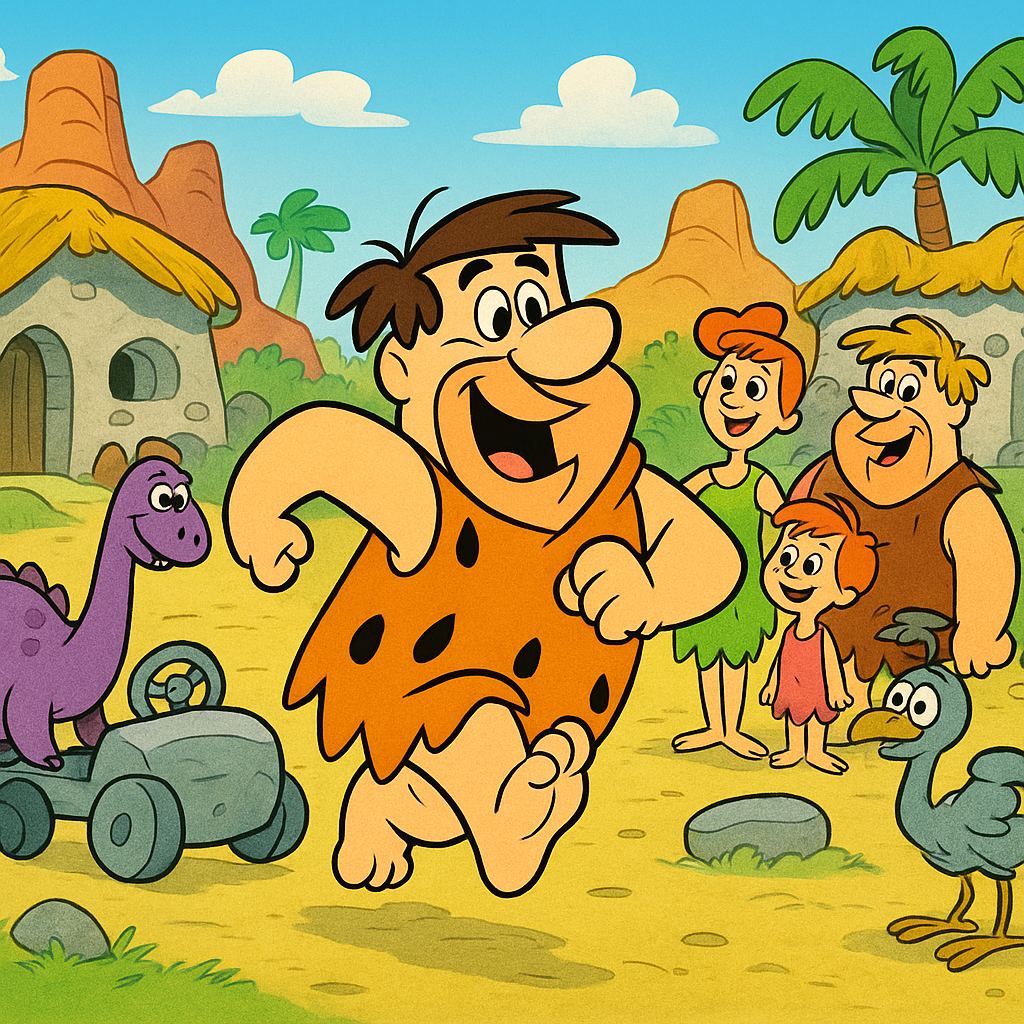


--- Article Output (Markdown) ---





Fred Flintstone misadventures: key facts, statistics, themes, and source URLs.

1. Overview
- Fred Flintstone: main character and patriarch of the Flintstone family.
- First appeared in the 1959 pilot “The Flagstones” and the 1960 series “The Flintstone Flyer.”
- Occupation: Crane operator at Slate Rock and Gravel Company in Bedrock.
- Family: Wife Wilma, daughter Pebbles, best friend Barney Rubble.
- Signature catchphrase: “Yabba-Dabba-Doo!”

2. Key Themes
- Humorous domestic misadventures: Episodes often center on Fred’s workplace mishaps, household blunders, and well-meaning schemes gone wrong.
- Family and friendship: Core focus on Fred’s relationships with Wilma, Pebbles, Barney, and Betty.
- Prehistoric twist: Use of Stone Age puns—animals as appliances, bronto-cranes, foot-powered cars.

3. Notable Data
- Original run: 1960–1966 (prime-time animated sitcom pioneer)
- Seasons: 6
- Episodes: 166
- Production: Hanna-Barbera Productions
- Cultural impact: Spawned spin-offs, merchandise, and enduring pop-culture references.

4. Representative Misadventures
- “Hot Lips Hannigan” (S1E10): Fred’s disastrous jazz band stint.
- “The Swimming Pool” (S2E11): Fred’s jealous antics lead to a flooded pool.
- “Little Bamm-Bamm” (S3E14): Fred’s attempt to impress neighbors by fostering a child.

5. Sources
- https://en.wikipedia.org/wiki/Fred_Flintstone
- https://en.wikipedia.org/wiki/The_Flintstones
- https://facts.net/lifestyle/entertainment/22-facts-about-fred-flintstone-the-flintstones/

In [26]:
# Orchestrator run cell — set `topic` and run to produce article + image
# Edit the `topic` variable below to run a different topic. If left empty, a default will be used.
topic = "Fred Flinstone misadventures"  # <-- replace this text with your topic

from agents import trace
import base64
from IPython.display import Markdown, HTML, display

print('Running orchestrator for topic:', topic)
with trace("Article Writer Run", group_id="ManualRun"):
    result = await Runner.run(orchestrator_agent, input=topic, max_turns=40)

print('Last agent:', getattr(getattr(result, 'last_agent', None), 'name', 'N/A'))

# Embed local hero_image.png if present (image_agent saves this file)
img_html = None
try:
    with open('hero_image.png', 'rb') as f:
        img_b64 = base64.b64encode(f.read()).decode('utf-8')
        img_html = f'<img src="data:image/png;base64,{img_b64}" alt="Hero Image" width="800"/>'
except Exception as e:
    print('No local hero_image.png found or failed to read it:', e)

# Clean and display the orchestrator output, embedding the image above the markdown
clean_output = getattr(result, 'final_output', str(result))
clean_output = clean_output.replace('sandbox:/', '')

if img_html:
    # remove markdown image reference if present
    clean_output = clean_output.replace('![hero image](hero_image.png)', '')
    display(HTML(img_html))

print('\n--- Article Output (Markdown) ---\n')
display(Markdown(clean_output))


In [27]:
# Diagnostics for name/Agent/result issues
import inspect, sys
print("Python executable:", sys.executable)
print("Agent defined?", 'Agent' in globals())
print("choose_writer defined?", 'choose_writer' in globals())
print("result defined?", 'result' in globals())
if 'Agent' in globals():
    print("Agent object:", inspect.signature(Agent))
else:
    print("Agent not found; ensure the import cell ran.")

Python executable: /Users/hectoraltamira/AI-Engineering/AI Engineering Part 2/ai_env/bin/python
Agent defined? True
choose_writer defined? True
result defined? True
Agent object: (name: 'str', handoff_description: 'str | None' = None, tools: 'list[Tool]' = <factory>, mcp_servers: 'list[MCPServer]' = <factory>, mcp_config: 'MCPConfig' = <factory>, instructions: 'str | Callable[[RunContextWrapper[TContext], Agent[TContext]], MaybeAwaitable[str]] | None' = None, prompt: 'Prompt | DynamicPromptFunction | None' = None, handoffs: 'list[Agent[Any] | Handoff[TContext, Any]]' = <factory>, model: 'str | Model | None' = None, model_settings: 'ModelSettings' = <factory>, input_guardrails: 'list[InputGuardrail[TContext]]' = <factory>, output_guardrails: 'list[OutputGuardrail[TContext]]' = <factory>, output_type: 'type[Any] | AgentOutputSchemaBase | None' = None, hooks: 'AgentHooks[TContext] | None' = None, tool_use_behavior: "Literal['run_llm_again', 'stop_on_first_tool'] | StopAtTools | ToolsToFin